In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.pyplot as plt

### Importing the Dataset

In [5]:
dogbreedData = pd.read_csv("./dog-breed-identification/labels.csv")
print("Shape:", dogbreedData.shape)

Shape: (10222, 2)


In [6]:
dogbreedData.head(5)

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


### Linking Images from the Train Folder to the ids of the labels dataset

In [7]:
dogbreedData['file_path'] = './dog-breed-identification/train/' + dogbreedData['id'] + '.jpg'

### Test and preview the first image in the dataset to see if this linking worked

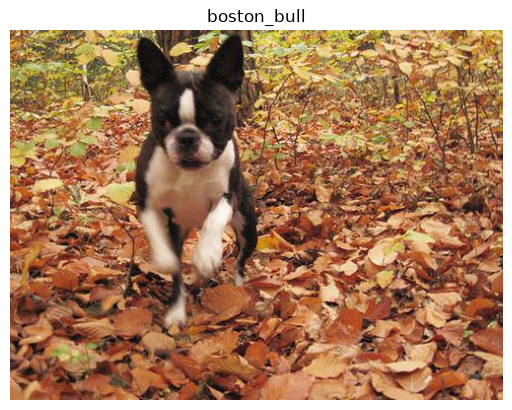

In [8]:
first_image = dogbreedData['file_path'].iloc[0]
first_breed = dogbreedData['breed'].iloc[0]

img = Image.open(first_image)
plt.imshow(img)
plt.title(first_breed)
plt.axis('off')
plt.show()

### Convert image to numerical values so that Machine Learning can use them, and adjust the image configurations and size.

In [9]:
import contextlib
import io
import torch
import torch.nn as nn
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    model = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

model.fc = nn.Identity()
model = model.to(device)
model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: mps


### Converts image to RGB and applies the transformation function from the previous cell, then creates a new dataset with the new numerical features.

In [10]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

class DogDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['file_path']
        with Image.open(img_path) as image:
            image = image.convert("RGB")
            if self.transform:
                image = self.transform(image)
        return image

dog_dataset = DogDataset(dogbreedData, transform=transform)
dataloader = DataLoader(dog_dataset, batch_size=64, shuffle=False, num_workers=0)

features_list = []

with torch.inference_mode():
    for batch_idx, batch_images in enumerate(dataloader):
        batch_images = batch_images.to(device)
        outputs = model(batch_images) 
        features_list.append(outputs.cpu().numpy())
        
        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(dataloader):
            print(f"Processed batch {batch_idx + 1} / {len(dataloader)}")

X_features = np.vstack(features_list)
y_labels = dogbreedData['breed'].values

print("X_features shape:", X_features.shape)
print("y_labels shape:", y_labels.shape)

Processed batch 10 / 160
Processed batch 20 / 160
Processed batch 30 / 160
Processed batch 40 / 160
Processed batch 50 / 160
Processed batch 60 / 160
Processed batch 70 / 160
Processed batch 80 / 160
Processed batch 90 / 160
Processed batch 100 / 160
Processed batch 110 / 160
Processed batch 120 / 160
Processed batch 130 / 160
Processed batch 140 / 160
Processed batch 150 / 160
Processed batch 160 / 160
X_features shape: (10222, 2048)
y_labels shape: (10222,)


### Implement KNN Classifier using the features extracted by CNN

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X_features, y_labels, test_size=0.2, random_state=42, stratify=y_labels)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_preds = knn.predict(X_test_scaled)
print("KNN Accuracy:", accuracy_score(y_test, knn_preds))

KNN Accuracy: 0.8132029339853301


### Implement Decision Tree to compare accuracy to KNN

In [12]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_preds = dt.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, dt_preds))


Decision Tree Accuracy: 0.552078239608802


### Save the trained model so it can be exported and used in an app

In [ ]:
import joblib

joblib.dump(scaler, 'feature_scaler.pkl')
joblib.dump(knn, 'dog_breed_model.pkl')